# Diagnóstico de la cobertura taxonómica, geográfica y de esfuerzo de recolección de especímenes en Colombia

**Proyecto final · Herramientas Computacionales 2026-2** · Equipo: Marvin Santiago Londoño Serna, Nicolás Blandón Berrío y Alejandro Muñóz Carmona

Este cuaderno responde cuatro preguntas sobre la base de datos *Distribución y recolección de especímenes*:

1. **Calidad taxonómica:** ¿qué proporción de los registros llega a nivel de especie?
2. **Esfuerzo y riqueza espaciales:** ¿dónde se concentra la recolección y dónde se acumula más riqueza registrada?
3. **Completitud del muestreo:** ¿las curvas de acumulación de cada grupo se acercan a estabilizarse?
4. **Perfil por expediente:** ¿cómo difieren los proyectos en composición y diversidad?

## Antes de empezar (Google Colab)

1. En **Entorno de ejecución → Cambiar tipo de entorno de ejecución**, selecciona **R**.
2. Abre el panel de archivos (icono de carpeta, a la izquierda) y **sube el archivo Excel** (`.xlsx`) tal como lo descargaste. Se guarda en `/content` y el cuaderno lo detecta solo, sin importar el nombre.
3. Ejecuta las celdas **en orden**. La primera instala paquetes y puede tardar un par de minutos.

**Una fila no es un sitio:** hay 2.836 filas pero solo 636 coordenadas distintas, así que los análisis cuentan puntos únicos y pares (punto, taxón), no filas.

## 0. Paquetes

`readxl` lee el Excel y `ggplot2` dibuja. `maps` es opcional: solo dibuja el contorno de Colombia en los mapas.

In [1]:
for (paquete in c("readxl", "ggplot2")) {
  if (!requireNamespace(paquete, quietly = TRUE)) {
    install.packages(paquete, repos = "https://cloud.r-project.org")
  }
}
if (!requireNamespace("maps", quietly = TRUE)) {
  try(install.packages("maps", repos = "https://cloud.r-project.org"), silent = TRUE)
}
library(ggplot2)
options(repr.plot.width = 9, repr.plot.height = 5.5)

## 1. Parámetros y lectura del Excel

Los parámetros modificables están al inicio de la celda. `NIVEL_ANALISIS = "genero"` incluye también los nombres que solo llegan a género.

Los encabezados originales tienen espacios y tildes (por ejemplo, `Grupo Biológico ` termina con un espacio), por eso se renombran por posición. Un **punto** es una coordenada única.

In [2]:
# --- Parámetros ----------------------------------------------------------------
NIVEL_ANALISIS     <- "especie"  # "especie": solo nombres a nivel de especie
                                 # "genero": especies y géneros, agrupados por género
PASO_GRADOS        <- 0.5        # tamaño de la celda de la cuadrícula (grados)
N_PERMUTACIONES    <- 200        # reordenamientos aleatorios de las curvas
MIN_PUNTOS_CURVA   <- 10         # mínimo de puntos para dibujar una curva
MIN_TAXONES_INDICE <- 5          # por debajo, los índices se marcan con cautela
SEMILLA            <- 2026       # para que las curvas sean reproducibles
LIMITES_LON <- c(-82.5, -66.5)   # rectángulo aproximado de Colombia
LIMITES_LAT <- c(-4.5, 13.5)

stopifnot(NIVEL_ANALISIS %in% c("especie", "genero"))

# --- Lectura -------------------------------------------------------------------
# Toma el primer .xlsx que encuentre en /content (Colab) o en la carpeta actual.
# Si hay varios, escribe aquí la ruta exacta: ARCHIVO <- "/content/mi_archivo.xlsx"
ARCHIVO <- list.files(c("/content", "datos", "."), pattern = "\\.xlsx$", full.names = TRUE)[1]
if (is.na(ARCHIVO)) {
  stop("No se encontró ningún .xlsx. Súbelo al panel de archivos de Colab, ",
       "espera a que termine la carga y vuelve a ejecutar.")
}
cat("Leyendo:", ARCHIVO, "\n")

datos <- as.data.frame(readxl::read_excel(ARCHIVO, sheet = 1))
stopifnot(ncol(datos) == 12)
names(datos) <- c("expediente", "solicitante", "proyecto", "grupo", "especie",
                  "observacion", "este", "norte", "objectid", "id_punto",
                  "lon", "lat")

# Quita espacios sobrantes en las columnas de texto.
columnas_texto <- c("expediente", "solicitante", "proyecto", "grupo", "observacion")
datos[columnas_texto] <- lapply(datos[columnas_texto],
                                function(v) trimws(gsub("\\s+", " ", v)))

stopifnot(all(is.finite(datos$lon)), all(is.finite(datos$lat)))
fuera <- datos$lon < LIMITES_LON[1] | datos$lon > LIMITES_LON[2] |
         datos$lat < LIMITES_LAT[1] | datos$lat > LIMITES_LAT[2]
if (any(fuera)) warning(sum(fuera), " registros quedan fuera del rectángulo de Colombia.")

# Un "punto" es una coordenada única: varias filas pueden compartirla.
datos$punto_id <- paste(round(datos$lon, 6), round(datos$lat, 6), sep = "_")

dir.create(file.path("resultados", "tablas"),  recursive = TRUE, showWarnings = FALSE)
dir.create(file.path("resultados", "figuras"), recursive = TRUE, showWarnings = FALSE)

cat("Filas:", nrow(datos), "\n")
cat("Puntos únicos (coordenadas):", length(unique(datos$punto_id)), "\n")
cat("Expedientes:", length(unique(datos$expediente)),
    "| Solicitantes:", length(unique(datos$solicitante)),
    "| Nombres distintos en 'especie':", length(unique(datos$especie)), "\n\n")
print(table(datos$grupo))

Leyendo: ./Distribución_y_recolección_de_especímenes_7352200361737316612.xlsx 
Filas: 2836 
Puntos únicos (coordenadas): 636 
Expedientes: 29 | Solicitantes: 13 | Nombres distintos en 'especie': 537 


       Animales          Hongos Microorganismos         Plantas   Varios Grupos 
           1157              69             519             952             139 


## 2. Funciones propias

`clasificar_nombres()` recibe un vector de nombres y devuelve género, nivel de resolución y un taxón normalizado. Las demás funciones calculan curvas de acumulación e índices de diversidad.

In [3]:
# --- Nombres taxonómicos -------------------------------------------------------
clasificar_nombres <- function(nombres) {
  # Devuelve una tabla con: genero, taxon, nivel y tentativo (cf./aff.).
  # nivel: "especie", "genero", "familia_o_superior", "sin_identificar" o "sin_dato".
  x <- gsub("\u00c2", "", nombres, fixed = TRUE)         # residuo de codificación
  x <- trimws(gsub("[[:space:]_]+", " ", x))             # saltos de línea, "_" y espacios
  x <- sub("^[[:upper:]]{2,}[[:upper:][:digit:]]*\\s+[0-9]+\\s+", "", x)  # "ATPH 55 Rhizopus sp." -> "Rhizopus sp."

  tentativo <- grepl("\\b(cf|aff)\\b", x, ignore.case = TRUE, perl = TRUE)
  x <- gsub("\\b(cf|aff)\\.?\\s+", "", x, ignore.case = TRUE, perl = TRUE)

  partes  <- strsplit(x, " ", fixed = TRUE)
  primera <- vapply(partes, function(p) p[1], character(1))
  epiteto <- tolower(vapply(partes, function(p) p[2], character(1)))
  genero  <- ifelse(is.na(primera), NA,
                    paste0(toupper(substring(primera, 1, 1)), tolower(substring(primera, 2))))

  es_palabra <- function(t) grepl("^[[:alpha:]]+(-[[:alpha:]]+)*$", t)
  epiteto_ok <- !is.na(epiteto) & es_palabra(epiteto) & nchar(epiteto) >= 2 &
                !grepl("^spp?\\.?[0-9]*$", epiteto)          # "sp", "sp.", "spp." no son epítetos

  # Cada línea sobrescribe a la anterior: la última tiene prioridad.
  nivel <- ifelse(epiteto_ok, "especie", "genero")
  nivel[grepl("(aceae|idae|inae|ales)$", tolower(genero))]        <- "familia_o_superior"
  nivel[!es_palabra(genero)]                                      <- "sin_identificar"
  nivel[grepl("no identificad|sin identificar", x, ignore.case = TRUE)] <- "sin_identificar"
  nivel[is.na(x) | x == ""]                                       <- "sin_dato"

  genero[nivel %in% c("sin_identificar", "sin_dato")] <- NA
  taxon <- ifelse(nivel == "especie", paste(genero, epiteto),
           ifelse(nivel == "genero",  paste(genero, "sp."),
           ifelse(nivel == "familia_o_superior", genero, NA)))
  data.frame(genero = genero, taxon = taxon, nivel = nivel, tentativo = tentativo)
}

resumir_resolucion <- function(columna) {
  # Filas y porcentaje de filas con nombre a nivel de especie, por categoría.
  grupo <- datos[[columna]]
  resultado <- data.frame(categoria = names(table(grupo)),
                          n_filas = as.vector(table(grupo)),
                          pct_especie = round(100 * as.vector(tapply(datos$nivel == "especie", grupo, mean)), 1))
  names(resultado)[1] <- columna
  resultado
}

# --- Curvas de acumulación -----------------------------------------------------
curva_acumulacion <- function(presencias, n_perm, semilla) {
  # 'presencias': una fila por par único (punto_id, clave_taxon).
  # Reordena los puntos al azar n_perm veces y cuenta los taxones distintos
  # vistos después de visitar 1, 2, 3, ... puntos.
  M <- table(presencias$punto_id, presencias$clave_taxon) > 0   # puntos x taxones
  n <- nrow(M)
  set.seed(semilla)
  acumulado <- t(replicate(n_perm, {
    primer_punto <- apply(M[sample(n), , drop = FALSE], 2, which.max)  # en qué visita aparece cada taxón
    cumsum(tabulate(primer_punto, nbins = n))
  }))
  data.frame(n_puntos   = seq_len(n),
             media      = colMeans(acumulado),
             limite_inf = unname(apply(acumulado, 2, quantile, probs = 0.025)),
             limite_sup = unname(apply(acumulado, 2, quantile, probs = 0.975)))
}

pendiente_final <- function(curva, fraccion = 0.1) {
  # Taxones nuevos por punto adicional en el último tramo de la curva.
  n <- nrow(curva)
  inicio <- max(1, n - max(1, ceiling(n * fraccion)))
  (curva$media[n] - curva$media[inicio]) / (n - inicio)
}

interpretar_pendiente <- function(p) {
  # Umbrales didácticos, no criterios estadísticos universales.
  ifelse(p > 0.5, "lejos de estabilizarse",
         ifelse(p >= 0.1, "ascenso moderado", "tendiendo a estabilizarse"))
}

# --- Índices de diversidad -----------------------------------------------------
indice_shannon <- function(abundancias) {
  # H' = -sum(p * ln p). NA si no hay taxones.
  a <- abundancias[abundancias > 0]
  if (length(a) == 0) return(NA_real_)
  p <- a / sum(a)
  -sum(p * log(p))
}

indice_simpson <- function(abundancias) {
  # Gini-Simpson: 1 - sum(p^2). NA si no hay taxones.
  a <- abundancias[abundancias > 0]
  if (length(a) == 0) return(NA_real_)
  p <- a / sum(a)
  1 - sum(p^2)
}

## 3. Pruebas de las funciones

Comparaciones con resultados que se pueden obtener a mano. Si alguna falla, el cuaderno se detiene con un error.

In [4]:
p <- clasificar_nombres(c("Lutzomyia longipalpis", "Lutzomyia Shannoni", "Bacillus",
                          "Culex spp.", "pernettya sp.", "Eunicea_asperula",
                          "Piper cf. carlossi", "ATPH 55 Rhizopus sp.",
                          "Especie no identificada", "Enterobacteriaceae", NA))
stopifnot(identical(p$nivel, c("especie", "especie", "genero", "genero", "genero",
                               "especie", "especie", "genero", "sin_identificar",
                               "familia_o_superior", "sin_dato")))
stopifnot(p$taxon[2] == "Lutzomyia shannoni", p$taxon[5] == "Pernettya sp.",
          p$taxon[6] == "Eunicea asperula", p$taxon[7] == "Piper carlossi",
          p$taxon[8] == "Rhizopus sp.", p$tentativo[7], !p$tentativo[1])

stopifnot(isTRUE(all.equal(indice_shannon(c(1, 1)), log(2))))
stopifnot(indice_shannon(c(5, 0)) == 0, is.na(indice_shannon(c(0, 0))))
stopifnot(isTRUE(all.equal(indice_simpson(c(1, 1)), 0.5)))
stopifnot(isTRUE(all.equal(indice_simpson(c(1, 1, 1, 1)), 0.75)))

# Curva con tres puntos: A tiene {1,2}, B tiene {2,3}, C tiene {1}. Siempre termina en 3 taxones.
prueba <- data.frame(punto_id    = c("A", "A", "B", "B", "C"),
                     clave_taxon = c("t1", "t2", "t2", "t3", "t1"))
stopifnot(tail(curva_acumulacion(prueba, 20, 1)$media, 1) == 3)

cat("Pruebas de las funciones superadas.\n")

Pruebas de las funciones superadas.


## 4. Línea 1 · Calidad taxonómica

Se normaliza cada nombre y se clasifica el nivel al que llega: especie, género, familia o superior, o sin identificar. La tabla `01_normalizacion_nombres.csv` permite auditar cada decisión.

--- Resolución taxonómica (porcentaje de filas) ---

           Especie             Género Familia o superior    Sin identificar 
              66.5               27.5                0.1                6.0 
          Sin dato 
               0.0 

--- Resolución por solicitante ---
                                                                            solicitante
1                                                                           Andrea Niño
2                                 Corporacion para la investigacion de la Corrosion-CIC
3                           Instituto Amazónico De Investigaciones Científicas – Sinchi
4  Instituto de Investigaciones Marinas y Costeras José Benito Vives de Andréis INVEMAR
5                                                      Pontificia Universidad Javeriana
6                                                              Universidad de Antioquia
7                                                              Universidad de la Sabana
8            

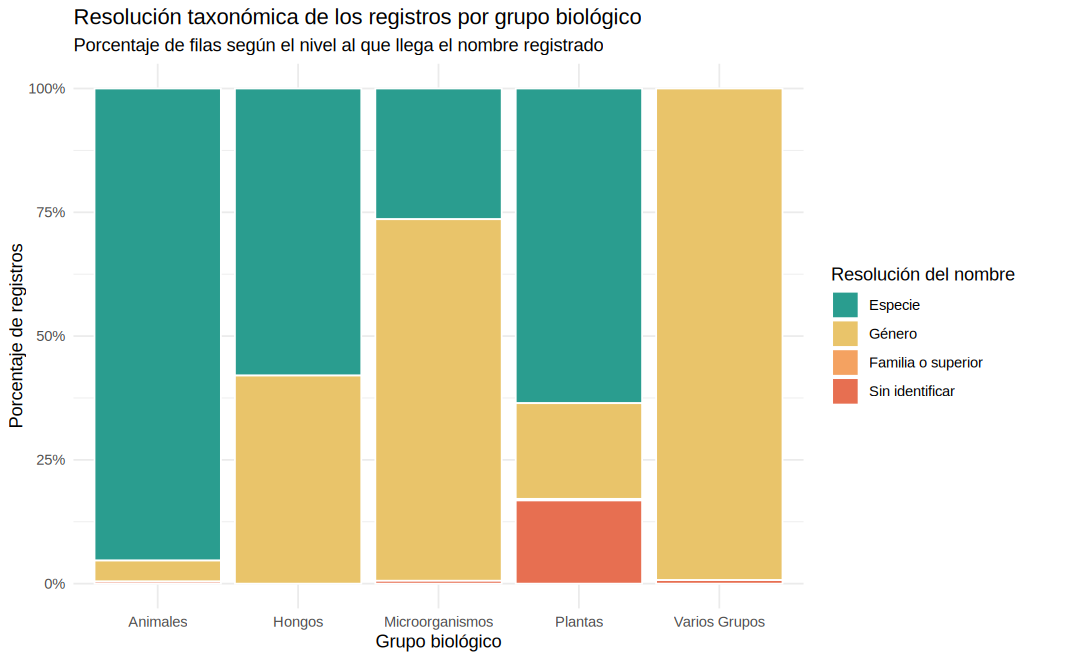

In [5]:
datos <- cbind(datos, clasificar_nombres(datos$especie))

NIVELES   <- c("especie", "genero", "familia_o_superior", "sin_identificar", "sin_dato")
ETIQUETAS <- c("Especie", "Género", "Familia o superior", "Sin identificar", "Sin dato")
COLORES   <- c("#2a9d8f", "#e9c46a", "#f4a261", "#e76f51", "grey70")
datos$nivel_etiqueta <- factor(datos$nivel, levels = NIVELES, labels = ETIQUETAS)

cat("--- Resolución taxonómica (porcentaje de filas) ---\n")
print(round(100 * prop.table(table(datos$nivel_etiqueta)), 1))

resolucion_solicitante <- resumir_resolucion("solicitante")
resolucion_expediente  <- resumir_resolucion("expediente")
cat("\n--- Resolución por solicitante ---\n")
print(resolucion_solicitante)

figura_resolucion <- ggplot(datos, aes(x = grupo, fill = nivel_etiqueta)) +
  geom_bar(position = "fill", color = "white") +
  scale_y_continuous(labels = scales::percent) +
  scale_fill_manual(values = setNames(COLORES, ETIQUETAS), name = "Resolución del nombre") +
  labs(title = "Resolución taxonómica de los registros por grupo biológico",
       subtitle = "Porcentaje de filas según el nivel al que llega el nombre registrado",
       x = "Grupo biológico", y = "Porcentaje de registros") +
  theme_minimal()
print(figura_resolucion)

## 5. Tabla de presencias para las líneas 2, 3 y 4

Unidad de análisis: pares únicos (punto, taxón). Así, 734 filas del mismo taxón en un mismo punto cuentan como una sola presencia. También se asigna cada punto a una celda de la cuadrícula.

In [6]:
# Clave del taxón según el nivel de análisis; NA = el registro se excluye.
if (NIVEL_ANALISIS == "especie") {
  datos$clave_taxon <- ifelse(datos$nivel == "especie", datos$taxon, NA)
} else {
  datos$clave_taxon <- ifelse(datos$nivel %in% c("especie", "genero"), datos$genero, NA)
}
cat("Nivel de análisis:", NIVEL_ANALISIS, "\n")
cat("Filas usadas:", sum(!is.na(datos$clave_taxon)), "de", nrow(datos), "\n")

# Cuadrícula: el origen es el múltiplo del paso inmediatamente inferior al mínimo.
lon_ref <- floor(min(datos$lon) / PASO_GRADOS) * PASO_GRADOS
lat_ref <- floor(min(datos$lat) / PASO_GRADOS) * PASO_GRADOS
datos$ix <- floor((datos$lon - lon_ref) / PASO_GRADOS)
datos$iy <- floor((datos$lat - lat_ref) / PASO_GRADOS)

presencias <- unique(datos[!is.na(datos$clave_taxon),
                           c("punto_id", "grupo", "expediente", "ix", "iy", "clave_taxon")])
cat("Pares únicos (punto, taxón):", nrow(presencias), "\n")

Nivel de análisis: especie 
Filas usadas: 1885 de 2836 
Pares únicos (punto, taxón): 664 


## 6. Línea 2 · Esfuerzo y riqueza por celda

Se cuentan puntos únicos y taxones por celda. El mapa de riqueza refleja sobre todo el esfuerzo de recolección, no la riqueza real.

--- Concentración del esfuerzo (celdas de 0.5 grados) ---
Celdas ocupadas: 77 
Celdas que reúnen el 50 % de los puntos: 8 
Celdas que reúnen el 80 % de los puntos: 26 
Celdas con un solo punto: 21 


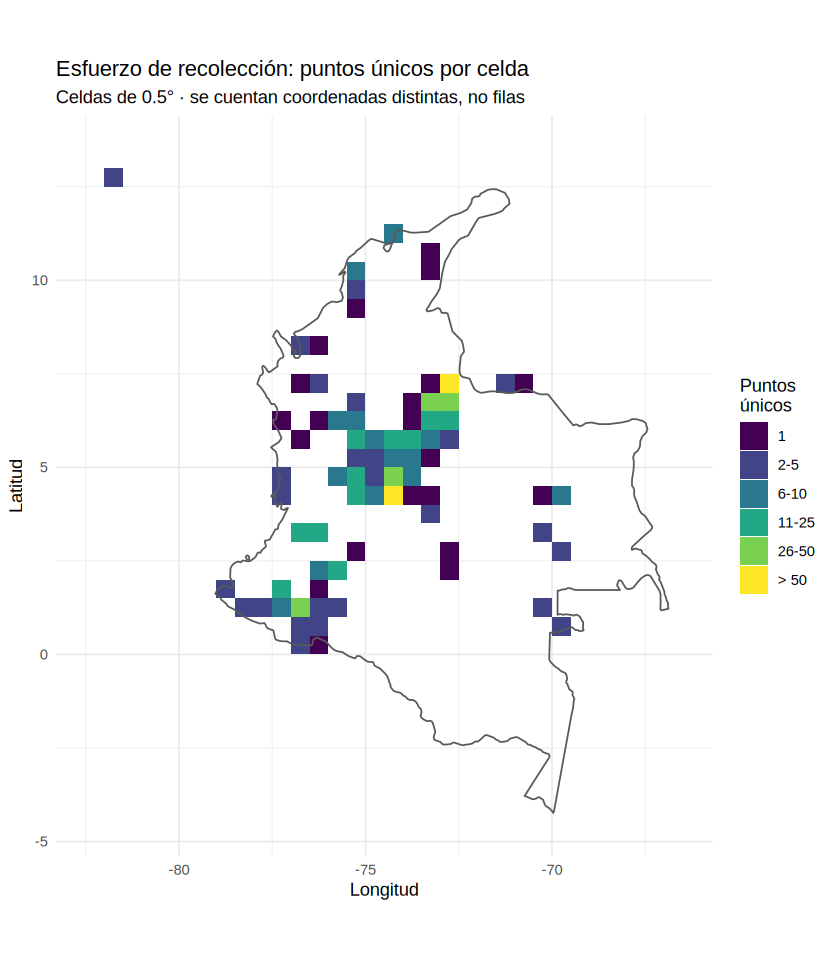

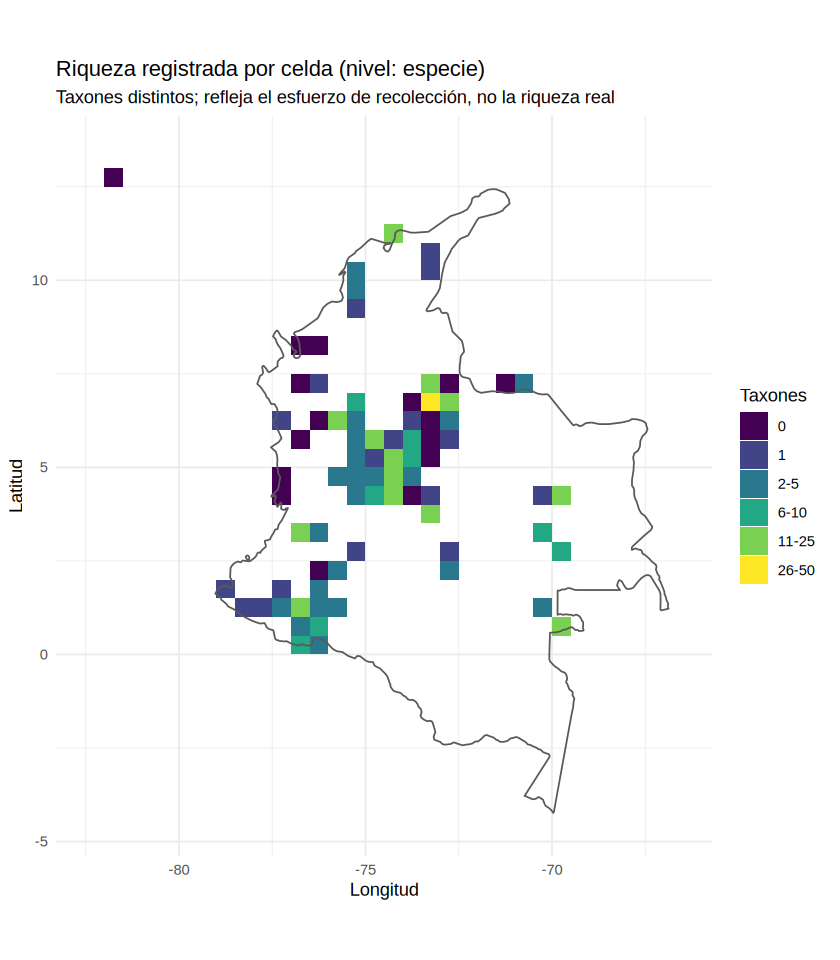

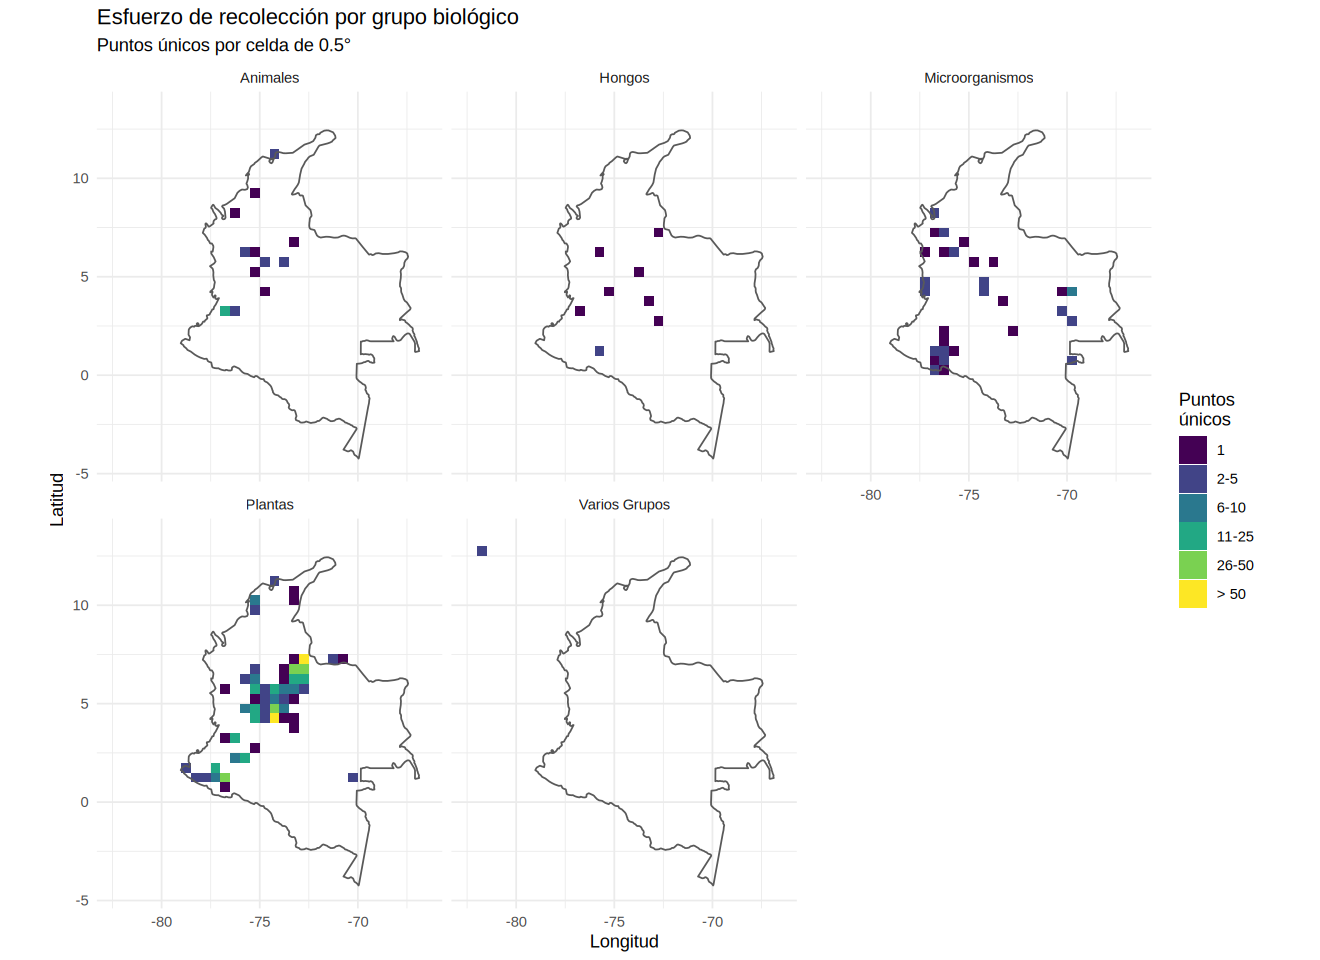

In [7]:
clasificar_conteo <- function(x) {
  cut(x, breaks = c(-Inf, 0, 1, 5, 10, 25, 50, Inf),
      labels = c("0", "1", "2-5", "6-10", "11-25", "26-50", "> 50"))
}

mapa_celdas <- function(tabla, columna, titulo, subtitulo, leyenda) {
  tabla$clase <- tabla[[columna]]
  p <- ggplot(tabla, aes(x = lon_centro, y = lat_centro, fill = clase)) +
    geom_tile(width = PASO_GRADOS, height = PASO_GRADOS)

  if (!is.null(capa_pais)) {
    p <- p + capa_pais
  }

  p +
    scale_fill_viridis_d(name = leyenda) +
    coord_quickmap(xlim = LIMITES_LON, ylim = LIMITES_LAT) +
    labs(title = titulo, subtitle = subtitulo, x = "Longitud", y = "Latitud") +
    theme_minimal()
}

# Puntos únicos y taxones por celda.
celdas <- aggregate(punto_id ~ ix + iy, data = datos, FUN = function(v) length(unique(v)))
names(celdas)[3] <- "n_puntos"
taxones_celda <- aggregate(clave_taxon ~ ix + iy, data = presencias,
                           FUN = function(v) length(unique(v)))
names(taxones_celda)[3] <- "n_taxones"
celdas <- merge(celdas, taxones_celda, by = c("ix", "iy"), all.x = TRUE)
celdas$n_taxones[is.na(celdas$n_taxones)] <- 0
celdas$lon_centro <- lon_ref + (celdas$ix + 0.5) * PASO_GRADOS
celdas$lat_centro <- lat_ref + (celdas$iy + 0.5) * PASO_GRADOS
celdas$clase_puntos  <- clasificar_conteo(celdas$n_puntos)
celdas$clase_taxones <- clasificar_conteo(celdas$n_taxones)

# Concentración del esfuerzo: ¿cuántas celdas reúnen la mitad y el 80 % de los puntos?
acumulado_puntos <- cumsum(sort(celdas$n_puntos, decreasing = TRUE)) / sum(celdas$n_puntos)
cat("--- Concentración del esfuerzo (celdas de", PASO_GRADOS, "grados) ---\n")
cat("Celdas ocupadas:", nrow(celdas), "\n")
cat("Celdas que reúnen el 50 % de los puntos:", which(acumulado_puntos >= 0.5)[1], "\n")
cat("Celdas que reúnen el 80 % de los puntos:", which(acumulado_puntos >= 0.8)[1], "\n")
cat("Celdas con un solo punto:", sum(celdas$n_puntos == 1), "\n")

# Contorno de Colombia usando map_data de forma segura para evitar conflictos en facetas
capa_pais <- NULL
if (requireNamespace("maps", quietly = TRUE)) {
  colombia_datos <- map_data("world", region = "Colombia")
  capa_pais <- geom_polygon(data = colombia_datos, aes(x = long, y = lat, group = group),
                            fill = NA, colour = "grey35", inherit.aes = FALSE)
} else {
  message("Paquete 'maps' no instalado: los mapas se dibujan sin contorno del país.")
}

mapa_esfuerzo <- mapa_celdas(celdas, "clase_puntos",
  "Esfuerzo de recolección: puntos únicos por celda",
  paste0("Celdas de ", PASO_GRADOS, "° · se cuentan coordenadas distintas, no filas"),
  "Puntos\núnicos")
mapa_riqueza <- mapa_celdas(celdas, "clase_taxones",
  paste0("Riqueza registrada por celda (nivel: ", NIVEL_ANALISIS, ")"),
  "Taxones distintos; refleja el esfuerzo de recolección, no la riqueza real",
  "Taxones")

# Esfuerzo por grupo biológico (un panel por grupo).
celdas_grupo <- aggregate(punto_id ~ grupo + ix + iy, data = datos,
                          FUN = function(v) length(unique(v)))
names(celdas_grupo)[4] <- "n_puntos"
celdas_grupo$lon_centro <- lon_ref + (celdas_grupo$ix + 0.5) * PASO_GRADOS
celdas_grupo$lat_centro <- lat_ref + (celdas_grupo$iy + 0.5) * PASO_GRADOS
celdas_grupo$clase_puntos <- clasificar_conteo(celdas_grupo$n_puntos)
mapa_grupos <- mapa_celdas(celdas_grupo, "clase_puntos",
  "Esfuerzo de recolección por grupo biológico",
  paste0("Puntos únicos por celda de ", PASO_GRADOS, "°"),
  "Puntos\núnicos") + facet_wrap(~ grupo, ncol = 3)

options(repr.plot.width = 7, repr.plot.height = 8)
print(mapa_esfuerzo)
print(mapa_riqueza)
options(repr.plot.width = 11, repr.plot.height = 8)
print(mapa_grupos)
options(repr.plot.width = 9, repr.plot.height = 5.5)

## 7. Línea 3 · Curvas de acumulación por grupo

La banda es el rango del 95 % de los reordenamientos aleatorios, no un intervalo de confianza poblacional. Los umbrales de `interpretar_pendiente()` son didácticos.

Grupo omitido por tener pocos puntos: Hongos ( 8 puntos )

--- Curvas de acumulación (último 10 % de los puntos) ---
            grupo n_puntos n_taxones nuevos_taxones_por_punto_final
1        Animales       32        48                          1.156
2 Microorganismos       43        94                          1.821
3         Plantas      310       196                          0.444
                 lectura
1 lejos de estabilizarse
2 lejos de estabilizarse
3       ascenso moderado


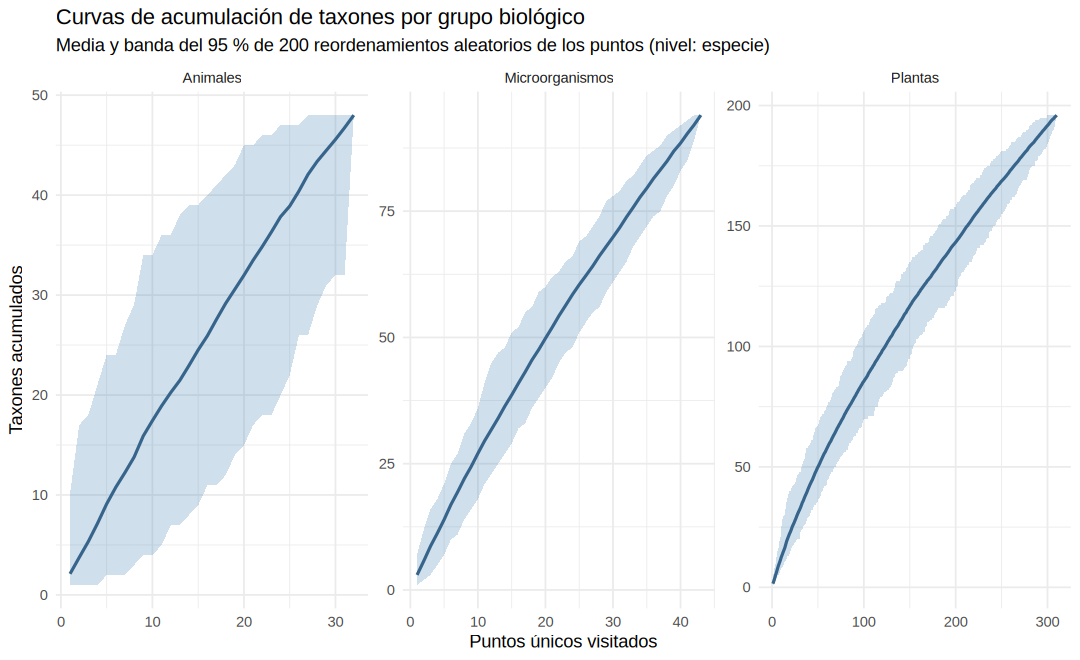

In [8]:
curvas <- data.frame()
resumen_curvas <- data.frame()
for (g in sort(unique(presencias$grupo))) {
  presencias_g <- presencias[presencias$grupo == g, ]
  n_puntos_g <- length(unique(presencias_g$punto_id))
  if (n_puntos_g < MIN_PUNTOS_CURVA) {
    cat("Grupo omitido por tener pocos puntos:", g, "(", n_puntos_g, "puntos )\n")
    next
  }
  curva <- curva_acumulacion(presencias_g, N_PERMUTACIONES, SEMILLA)
  curva$grupo <- g
  curvas <- rbind(curvas, curva)

  pendiente <- pendiente_final(curva)
  resumen_curvas <- rbind(resumen_curvas, data.frame(
    grupo = g,
    n_puntos = n_puntos_g,
    n_taxones = length(unique(presencias_g$clave_taxon)),
    nuevos_taxones_por_punto_final = round(pendiente, 3),
    lectura = interpretar_pendiente(pendiente)))
}
cat("\n--- Curvas de acumulación (último 10 % de los puntos) ---\n")
print(resumen_curvas)

figura_curvas <- ggplot(curvas, aes(x = n_puntos, y = media)) +
  geom_ribbon(aes(ymin = limite_inf, ymax = limite_sup), alpha = 0.25, fill = "steelblue") +
  geom_line(color = "steelblue4", linewidth = 0.9) +
  facet_wrap(~ grupo, scales = "free") +
  labs(title = "Curvas de acumulación de taxones por grupo biológico",
       subtitle = paste0("Media y banda del 95 % de ", N_PERMUTACIONES,
                         " reordenamientos aleatorios de los puntos (nivel: ", NIVEL_ANALISIS, ")"),
       x = "Puntos únicos visitados", y = "Taxones acumulados") +
  theme_minimal()
print(figura_curvas)

## 8. Línea 4 · Perfil por expediente e índices de diversidad

Sin abundancias reales, Shannon y Simpson se calculan con **incidencia**: número de puntos únicos donde aparece cada taxón dentro del expediente.

--- Perfil por expediente ---
   expediente grupo_dominante n_filas n_puntos pct_especie n_taxones shannon
1  RGE0152-20          Hongos      14        6       100.0         2   0.637
2  RGE0152-21         Plantas     276      172        41.7        48   3.455
3  RGE0152-25        Animales    1089        7        95.9        24   3.178
4  RGE0152-26         Plantas      32       16       100.0         2   0.677
5  RGE0152-27         Plantas      20       12       100.0         2   0.679
6  RGE0152-29         Plantas      42        8        92.9        31   3.379
7  RGE0152-31         Plantas     126      123         0.0         0      NA
8  RGE0152-42         Plantas       2        2       100.0         2   0.693
9  RGE0154-05        Animales      10        2        90.0         5   1.561
10 RGE0156-13        Animales       4        4        50.0         2   0.693
11 RGE0156-15 Microorganismos       2        2       100.0         2   0.693
12 RGE0158-07 Microorganismos     341        8

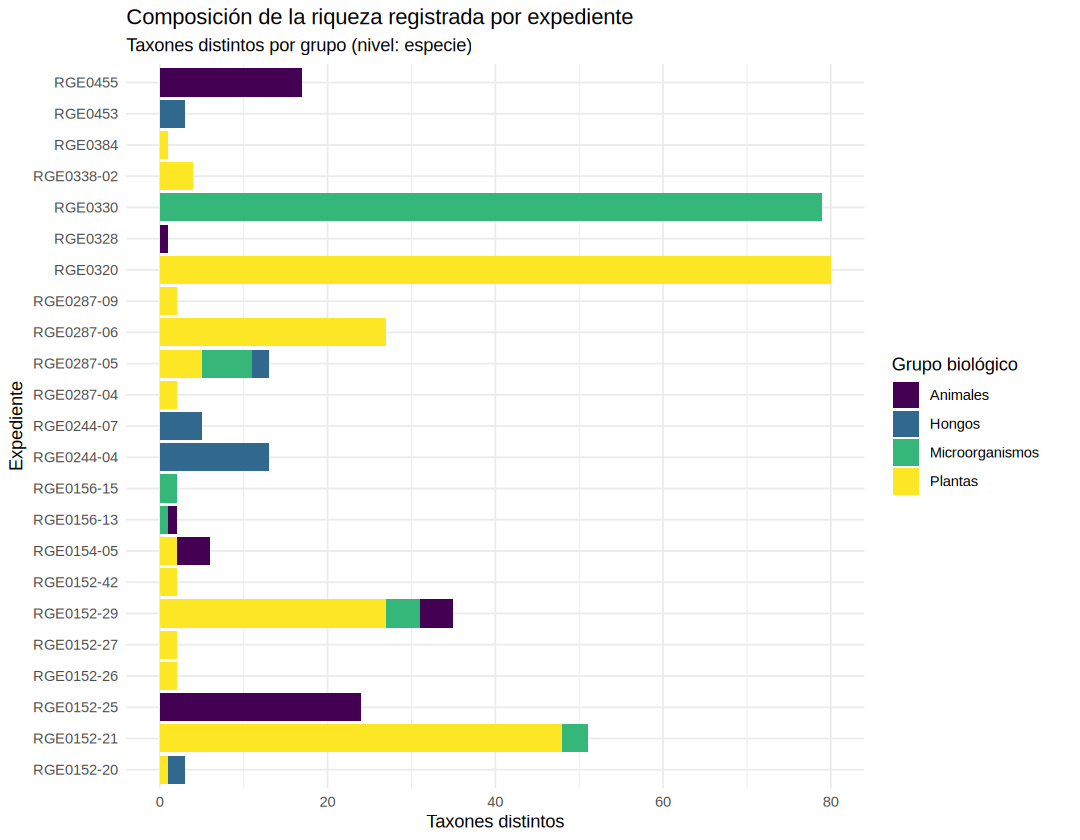

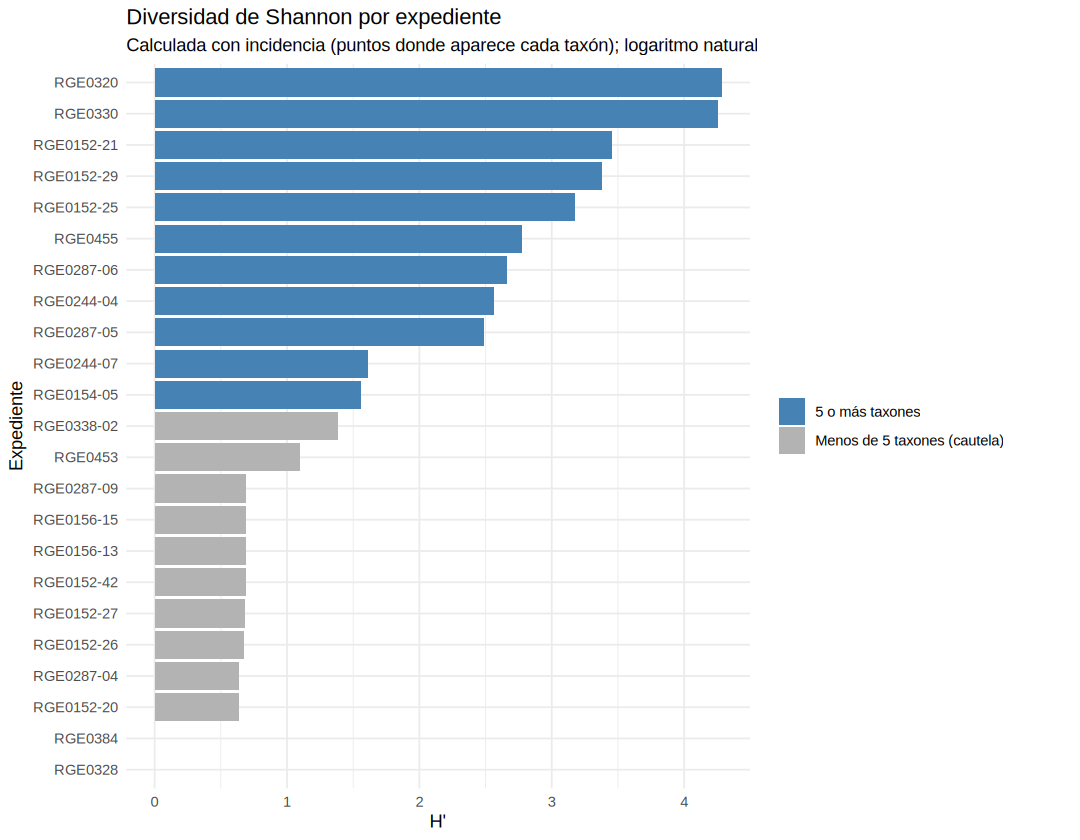

In [9]:
perfil <- data.frame()
for (e in sort(unique(datos$expediente))) {
  filas_e <- datos[datos$expediente == e, ]
  presencias_e <- unique(presencias[presencias$expediente == e, c("punto_id", "clave_taxon")])
  incidencia <- as.numeric(table(presencias_e$clave_taxon))   # puntos donde aparece cada taxón
  perfil <- rbind(perfil, data.frame(
    expediente = e,
    solicitante = filas_e$solicitante[1],
    grupo_dominante = names(which.max(table(filas_e$grupo))),
    n_filas = nrow(filas_e),
    n_puntos = length(unique(filas_e$punto_id)),
    pct_especie = round(100 * mean(filas_e$nivel == "especie"), 1),
    n_taxones = length(incidencia),
    shannon = round(indice_shannon(incidencia), 3),
    simpson = round(indice_simpson(incidencia), 3)))
}
perfil$interpretar_con_cautela <- perfil$n_taxones < MIN_TAXONES_INDICE

cat("--- Perfil por expediente ---\n")
print(perfil[, c("expediente", "grupo_dominante", "n_filas", "n_puntos",
                 "pct_especie", "n_taxones", "shannon", "simpson")])

con_taxones <- perfil[perfil$n_taxones > 0, ]
cat("\nCorrelación de Spearman entre puntos y taxones por expediente:",
    round(cor(con_taxones$n_puntos, con_taxones$n_taxones, method = "spearman"), 2), "\n")

# Composición: taxones distintos por grupo dentro de cada expediente.
composicion <- aggregate(clave_taxon ~ expediente + grupo, data = presencias,
                         FUN = function(v) length(unique(v)))
names(composicion)[3] <- "n_taxones"
figura_composicion <- ggplot(composicion, aes(x = expediente, y = n_taxones, fill = grupo)) +
  geom_col() +
  coord_flip() +
  scale_fill_viridis_d(name = "Grupo biológico") +
  labs(title = "Composición de la riqueza registrada por expediente",
       subtitle = paste0("Taxones distintos por grupo (nivel: ", NIVEL_ANALISIS, ")"),
       x = "Expediente", y = "Taxones distintos") +
  theme_minimal()

# Shannon por expediente, marcando los que tienen pocos taxones.
etiqueta_ok      <- paste0(MIN_TAXONES_INDICE, " o más taxones")
etiqueta_cautela <- paste0("Menos de ", MIN_TAXONES_INDICE, " taxones (cautela)")
perfil_grafico <- perfil[!is.na(perfil$shannon), ]
perfil_grafico$robustez <- ifelse(perfil_grafico$interpretar_con_cautela, etiqueta_cautela, etiqueta_ok)
perfil_grafico$expediente <- reorder(perfil_grafico$expediente, perfil_grafico$shannon)
figura_shannon <- ggplot(perfil_grafico, aes(x = expediente, y = shannon, fill = robustez)) +
  geom_col() +
  coord_flip() +
  scale_fill_manual(values = setNames(c("steelblue", "grey70"), c(etiqueta_ok, etiqueta_cautela)),
                    name = NULL) +
  labs(title = "Diversidad de Shannon por expediente",
       subtitle = "Calculada con incidencia (puntos donde aparece cada taxón); logaritmo natural",
       x = "Expediente", y = "H'") +
  theme_minimal()

options(repr.plot.width = 9, repr.plot.height = 7)
print(figura_composicion)
print(figura_shannon)
options(repr.plot.width = 9, repr.plot.height = 5.5)

## 9. Guardar resultados

Las tablas y figuras quedan en la carpeta `resultados/` del entorno de Colab (panel de archivos). La última línea las comprime en `resultados.zip` para descargarlas (clic derecho → Descargar).

In [10]:
tablas <- list(
  "01_normalizacion_nombres"   = unique(datos[, c("especie", "nivel", "genero", "taxon", "tentativo")]),
  "02_resolucion_solicitante"  = resolucion_solicitante,
  "03_resolucion_expediente"   = resolucion_expediente,
  "04_celdas_esfuerzo_riqueza" = celdas[, c("ix", "iy", "lon_centro", "lat_centro", "n_puntos", "n_taxones")],
  "05_curvas_acumulacion"      = curvas,
  "06_resumen_curvas"          = resumen_curvas,
  "07_perfil_expedientes"      = perfil)
for (nombre in names(tablas)) {
  write.csv(tablas[[nombre]], file.path("resultados", "tablas", paste0(nombre, ".csv")),
            row.names = FALSE, fileEncoding = "UTF-8")
}

figuras <- list(
  "01_resolucion_taxonomica"   = figura_resolucion,
  "02_mapa_esfuerzo"           = mapa_esfuerzo,
  "03_mapa_riqueza"            = mapa_riqueza,
  "04_mapa_esfuerzo_por_grupo" = mapa_grupos,
  "05_curvas_acumulacion"      = figura_curvas,
  "06_composicion_expedientes" = figura_composicion,
  "07_shannon_expedientes"     = figura_shannon)
for (nombre in names(figuras)) {
  ggsave(file.path("resultados", "figuras", paste0(nombre, ".png")), plot = figuras[[nombre]],
         width = 9, height = 7, dpi = 150)
}

writeLines(capture.output(sessionInfo()), file.path("resultados", "sessionInfo.txt"))
system("zip -rq resultados.zip resultados")
cat("Listo. Resultados en 'resultados/' y comprimidos en 'resultados.zip'.\n")

Listo. Resultados en 'resultados/' y comprimidos en 'resultados.zip'.


## Limitaciones

- Los registros reflejan dónde se solicitaron y reportaron recolecciones, no un muestreo sistemático.
- Sin un polígono oficial del territorio no se puede afirmar qué regiones quedan sin cubrir.
- Los nombres no se validan contra un catálogo taxonómico: sinónimos o errores tipográficos cuentan como taxones distintos.
- Con pocos puntos las curvas no son confiables; esos grupos se omiten.
- Shannon y Simpson basados en incidencia no son comparables con valores calculados con abundancias.

## Uso de herramientas de inteligencia artificial

para este proyecto se complemento parte del codigo con ayuda de la inteligencia artificial denominada como "Claude"

## Referencias

- R Core Team. *R: A Language and Environment for Statistical Computing.* https://www.R-project.org/
- Wickham, H. (2016). *ggplot2: Elegant Graphics for Data Analysis.* Springer-Verlag New York.
- Wickham, H. y Bryan, J. *readxl: Read Excel Files.* https://readxl.tidyverse.org/
- Material del curso Herramientas Computacionales 2026-2 (notebooks 03 a 07).
- Base de datos SIAC para los datos usados en el programa